             sum [Mm³/year]  mean [m³/h]  min [m³/h]  max [m³/h]  \
Large City             15.0      1712.33      480.22     2954.39   
Medium City             5.0       570.78      131.55     1140.57   
Small City              1.0       114.16       18.84      271.40   

             peakfactor [-]  
Large City             1.73  
Medium City            2.00  
Small City             2.38  


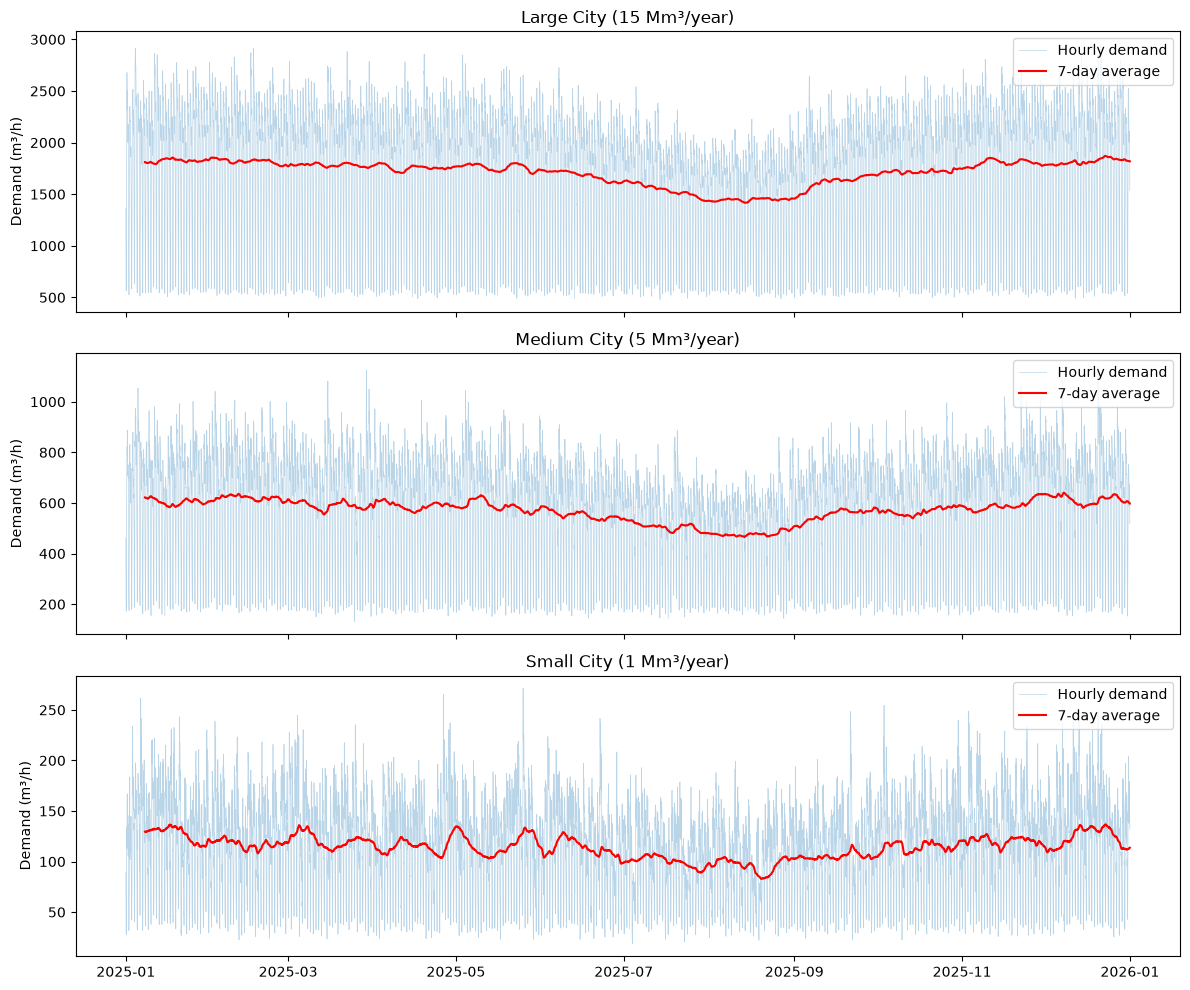

In [5]:
import numpy as np                      
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- TIMESERIES FROM MURCIA DATA ----------------

# ---------------- 1. Defining the Parameters ----------------

YEAR = 2025                             
CITIES = {"Large City": 15e6,           
          "Medium City": 5e6,
          "Small City": 1e6}

# ---------------- 2. Day pattern ----------------

# Values that were read from Fig. 4 of the paper, representing the hourly demand in m³/h.
day = np.array([1100, 800, 600, 480, 470, 700, 1050, 1450, 1780, 2000, 2100, 2090,
                2050, 2000, 1970, 1930, 1880, 1800, 1740, 1750, 1800, 1800, 1600, 1350])

 # Figure 3 in the paper shows a weekend pattern that is slight higher than the weekday pattern, I approximated this to be 110% of the weekday pattern.
day_weekend = 1.1 * day   

# ---------------- 3. Seasonal behaviour --> also approximated from the paper: Note that the demand during summer months is lower due to vacation and other parameters ----------------

season_day   = [1,    60,   152,  182,  213,  227,  258,  305,  365]   # day of the year 
season_factor = [1.03, 1.00, 0.96, 0.83, 0.72, 0.70, 0.88, 0.98, 1.03]  # factor of the peak (dip in the summer months)

# ---------------- 4. Creating the time series ----------------

time = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31 23:00", freq="h")   # Every hour of the year (8760 time steps)
hour = time.hour.values                  # per time step the hour of the day (0-23)
weekend = time.dayofweek.values >= 5    # per time step True on Saturday or Sunday (weekend has a higher demand than weekdays)

# ---------------- 5. Normal pattern, without noise ----------------

pattern = np.where(weekend, day_weekend[hour], day[hour])    #If weekend is True then use the weekend pattern, else use the weekday pattern
season = np.interp(time.dayofyear, season_day, season_factor)   # Seasonal factor for each time step 
pattern = 470 + season * (pattern - 470)   # Apply seasonal factor only to demands above the base minimum.

# ---------------- 6. Adding noise and scaling for large, average and small cities for the model ----------------

rng = np.random.default_rng(42)         # random noise generator with a fixed seed such that every run gives the same noise.
data = {}                               # Per city the hourly time series
for naam, volume in CITIES.items():     # Repeat for every city 
    ruis = 0.03 * np.sqrt(13e6 / volume)                     # Noise factor: A smaller city has less consumers, so relatively more noise 
    per_day = np.repeat(rng.normal(0, 1.5 * ruis, len(time) // 24), 24)   # 1 number per day
    per_hour = rng.normal(0, ruis, len(time))                 # 1 number per hour
    q = pattern * (1 + per_day) * (1 + per_hour)              # pattern with hourly and daily noise incorporated
    data[naam] = pd.Series(q * volume / q.sum(), index=time) # scale such that sum over the year = annual volume; unit m³/h

# ---------------- 7. Making a table ----------------

tabel = pd.DataFrame(data).agg(["sum", "mean", "min", "max"]).T   # sum, mean, min, max per city
tabel["sum"] = tabel["sum"] / 1e6                        # sum to million m³
tabel["peakfactor"] = tabel["max"] / tabel["mean"]       # peak factor = max vs. mean

tabel = tabel.rename(columns={
    "sum": "sum [Mm³/year]",                # Assigning the correct units to every column
    "mean": "mean [m³/h]",
    "min": "min [m³/h]",
    "max": "max [m³/h]",
    "peakfactor": "peakfactor [-]"
})
print(tabel.round(2))

# ---------------- 8. Plotting  ----------------

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, (naam, s) in zip(axes, data.items()):
    ax.plot(s, alpha=0.3, linewidth=0.5, label="Hourly demand")
    ax.plot(s.rolling(24 * 7).mean(), color="red", label="7-day average")
    ax.set_title(f"{naam} ({s.sum() / 1e6:.0f} Mm³/year)")
    ax.set_ylabel("Demand (m³/h)")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Sla de uurlijkse reeksen van alle steden op in een CSV-bestand voor je simulator
df_export = pd.DataFrame(data)
df_export.to_csv("water_demand_profiles_2025.csv", index_label="tijd")

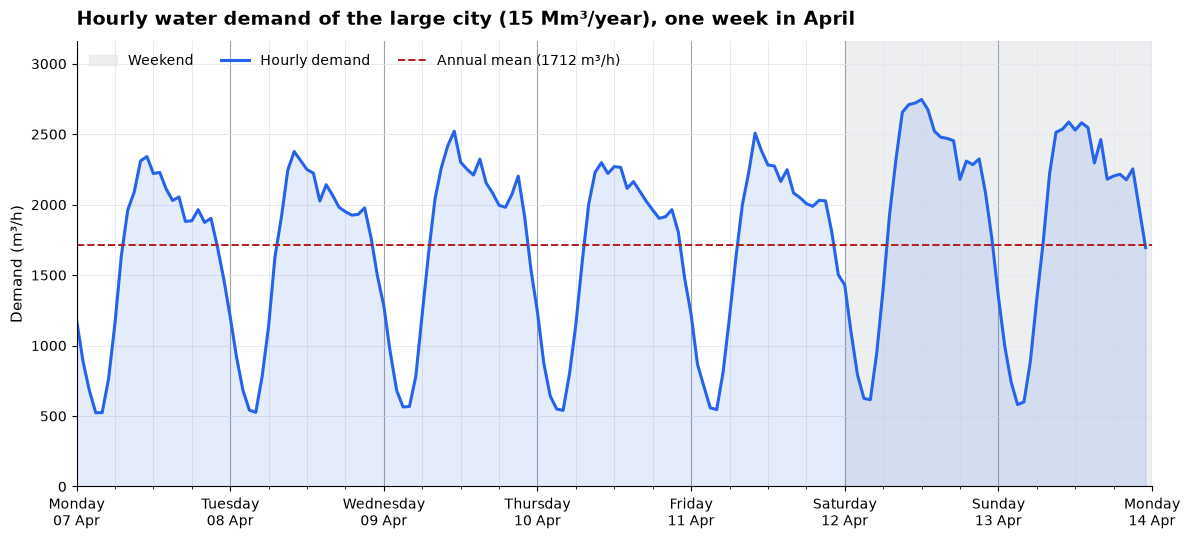

In [3]:
# ---------------- 9. Weekly pattern of one city ----------------
import matplotlib.dates as mdates

city = "Large City"
week = data[city].loc["2025-04-07":"2025-04-13 23:00"]          # Monday t/m Sunday
weekend_start, week_end = pd.Timestamp("2025-04-12"), pd.Timestamp("2025-04-14")

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.axvspan(weekend_start, week_end, color="#e5e7eb", alpha=0.7, label="Weekend", zorder=0)
ax.fill_between(week.index, week.values, color="#2563eb", alpha=0.12, zorder=1)
ax.plot(week.index, week.values, color="#2563eb", linewidth=2.2, zorder=2, label="Hourly demand")

ax.axhline(data[city].mean(), color="#b91c1c", linestyle="--", linewidth=1.4, zorder=2,
           label=f"Annual mean ({data[city].mean():.0f} m³/h)")

t_max, t_min = week.idxmax(), week.idxmin()



ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%A\n%d %b"))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax.grid(axis="x", which="major", color="#9ca3af", linewidth=0.8)
ax.grid(axis="x", which="minor", color="#e5e7eb", linewidth=0.6)
ax.grid(axis="y", color="#e5e7eb", linewidth=0.6)
ax.set_axisbelow(True)
ax.set_xlim(week.index[0], week_end)
ax.set_ylim(0, week.max() * 1.15)

ax.set_ylabel("Demand (m³/h)", fontsize=11)
ax.set_title("Hourly water demand of the large city (15 Mm³/year), one week in April",
             fontsize=14, fontweight="bold", loc="left", pad=12)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1), ncol=3, frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig("weekly_pattern_large_city.png", dpi=300)
plt.show()